# Tutorial 4 — The colour term

Gaia measures the along-scan position of a star on each CCD. The measured position depends a little on the colour of the star, because the optics spread blue and red light differently. Gaia corrects for this with an assumed colour. If the assumed colour is not the true colour, each position is displaced by a small amount.

The DR4 epoch astrometry gives what you need to treat this:

| field | per | unit | meaning |
|---|---|---|---|
| `colour_factor_al` | CCD | mas µm | how much the position moves per unit of colour error |
| `nu_eff_used_in_astrometry` | transit | µm⁻¹ | the colour that Gaia assumed, $\nu_\mathrm{used}$ |

The colour is the **effective wavenumber** $\nu_\mathrm{eff}$: the mean of $1/\lambda$ over the light of the star. A blue star has a larger $\nu_\mathrm{eff}$ than a red star. For a star of true colour $\nu$, the published position is

$$ w_\mathrm{pub} = \mathrm{model} + s \cdot \texttt{colour\_factor\_al} \cdot (\nu - \nu_\mathrm{used}), \qquad s = -1 . $$

The model is linear in $\nu$. So the colour is one more column of the design matrix, and one more number in the linear solve.

This tutorial uses three sources of the public pre-release:

1. **LSPM J1324+6124**, the single star of tutorial 1: the six-parameter fit.
2. **Gaia-4**, the planet host of tutorial 2: the orbit with a free colour.
3. **Gaia BH3**, the black-hole binary of tutorial 3: the same, and a warning.

Units: positions in **mas**, colour factors in **mas µm**, colours in **µm⁻¹**, times in **MJD (TCB)**, periods in **days**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import minimize

from orblet.constants import MJD_J2017_5_TCB, COLOUR_FACTOR_AL_SIGN
from orblet import (resolve_epochs_mjd, fit_astrometric_5param, astrometric_5param_design_matrix,
                    best_linear_params_ti, ti_to_kepler, colour_columns,
                    ColourTerm, DPAC_COLOUR_PRIOR_SIGMA)
from orblet.design import concat_columns

# The loader and the markdown helpers of tutorial 1.
from dr4_prerelease import (download_prerelease, read_prerelease, explode_transits,
                            matrix_markdown, params_markdown, source_id_of)

EPOCH_REF = MJD_J2017_5_TCB          # reference epoch of DR4, MJD (TCB)
table = read_prerelease(download_prerelease("_data"))
print("sign constant of orblet, s =", COLOUR_FACTOR_AL_SIGN)
print("prior width that reproduces Gaia's own colour fits:", DPAC_COLOUR_PRIOR_SIGMA, "per micron")

sign constant of orblet, s = -1
prior width that reproduces Gaia's own colour fits: 0.085 per micron


## 1. The colour fields in the file

`explode_transits` (tutorial 1) gives one datum per CCD. It now also returns the two colour inputs of orblet, one value per datum:

- `colour_factor_al`: the field of the file, unchanged;
- `nu_eff_used`: the value of the transit, repeated on its CCDs.

Look at them for the three sources.

| source | CCD data | assumed colour (1/um) | colour factor: 5 % | median | 95 % (mas um) |
|---|---:|---:|---:|---:|---:|
| LSPM J1324+6124 | 781 | 1.3964 | -2.50 | 1.10 | 4.26 |
| Gaia-4 | 824 | 1.3898 | -4.64 | 0.63 | 5.62 |
| Gaia BH3 | 558 | 1.4779 | -4.90 | 0.59 | 4.93 |

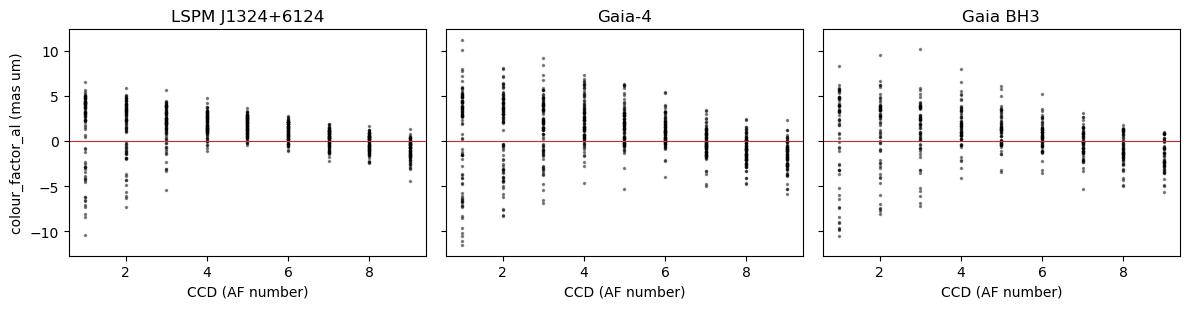

In [2]:
SOURCE_NAMES = ["LSPM J1324+6124", "Gaia-4", "Gaia BH3"]

# step 1, read the three sources: a table from the source name to its astrometry dict
astro_of = {}
for source_name in SOURCE_NAMES:
    astro_of[source_name] = explode_transits(table, source_id_of(source_name))

# step 2, one line of numbers per source
lines = ["| source | CCD data | assumed colour (1/um) | colour factor: 5 % | median | 95 % (mas um) |",
         "|---|---:|---:|---:|---:|---:|"]
for source_name in SOURCE_NAMES:
    astro = astro_of[source_name]
    factor = astro["colour_factor_al"]
    assumed_colours = np.unique(astro["nu_eff_used"])   # one value if all transits agree
    assert assumed_colours.size == 1 and np.all(np.isfinite(factor))
    low, median, high = np.percentile(factor, [5, 50, 95])
    lines.append(f"| {source_name} | {factor.size} | {assumed_colours[0]:.4f} "
                 f"| {low:.2f} | {median:.2f} | {high:.2f} |")
display(Markdown("\n".join(lines)))

# step 3, the colour factor of every datum against its CCD (1 to 9 are AF1 to AF9)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for axis, source_name in zip(axes, SOURCE_NAMES):
    astro = astro_of[source_name]
    axis.plot(astro["ccd_index"], astro["colour_factor_al"], ".", ms=3, color="k", alpha=0.4)
    axis.axhline(0.0, color="C3", lw=0.8)
    axis.set_title(source_name)
    axis.set_xlabel("CCD (AF number)")
axes[0].set_ylabel("colour_factor_al (mas um)")
plt.tight_layout()
plt.show()

What to see:

- The assumed colour is **one value per source**. Gaia took it from the BP and RP photometry.
- The colour factor is a few mas µm, with both signs. It changes from CCD to CCD and from transit to transit. This is what lets a fit separate the colour from the position: a position offset moves all CCDs of a transit together, a colour error does not.
- A colour error of 0.01 µm⁻¹ with a factor of 5 mas µm moves a position by 0.05 mas. That is comparable to the error of one CCD datum of these stars (0.08 mas).

## 2. The six-parameter fit of a single star

Tutorial 1 fitted five parameters to LSPM J1324+6124. Add the colour as a sixth. The design matrix gets one more column, **after** the five:

$$ \frac{\partial w}{\partial \nu} = s \cdot \texttt{colour\_factor\_al} . $$

`colour_columns` builds it. The sixth parameter is $\delta\nu = \nu - \nu_\mathrm{ref}$, the difference from the assumed colour ($\nu_\mathrm{ref}$ is the median of `nu_eff_used`).

In [3]:
astro = astro_of["LSPM J1324+6124"]
t_mjd = resolve_epochs_mjd(astro)

# step 1, the design matrix: the five columns of tutorial 1, then the colour column
X5 = astrometric_5param_design_matrix(t_mjd, astro["scan_angle"], astro["parallax_factor_al"],
                                      epoch_ref_mjd=EPOCH_REF)
colour_column = colour_columns(astro["colour_factor_al"])
X6 = concat_columns([X5, colour_column])
COLS6 = ["sin", "cos", "dt sin", "dt cos", "f_AL", "s x colour factor"]
display(matrix_markdown(X6, COLS6, n_rows=6, caption="Six-column design matrix of LSPM J1324+6124"))

**Six-column design matrix of LSPM J1324+6124** (shape 781 x 6)

| row | sin | cos | dt sin | dt cos | f_AL | s x colour factor |
|---|---:|---:|---:|---:|---:|---:|
| 0 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -4.4145 |
| 1 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -3.8187 |
| 2 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -2.0529 |
| 3 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -2.3393 |
| 4 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -1.7508 |
| 5 | 0.7411 | -0.6714 | -0.9065 | 0.8212 | -0.6236 | -1.0594 |
| ... | ... | ... | ... | ... | ... | ... |

The first six rows are the CCDs of one transit. The five columns of tutorial 1 repeat. The colour column does not: each CCD has its own factor.

You do not build this matrix yourself in a fit. `fit_astrometric_5param` takes the keyword `colour`:

| call | what it does |
|---|---|
| no `colour` | the five-parameter fit of tutorial 1, unchanged |
| `ColourTerm("free")` | fit the colour as a sixth parameter, no prior |
| `ColourTerm("free", prior_sigma=0.085)` | the same, with a Gaussian prior of that width around the assumed colour |
| `ColourTerm("fixed", nu_eff=...)` | move the data to a colour you give, then fit five parameters |

In [4]:
PARAMS5 = ["dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]
PARAMS6 = PARAMS5 + ["delta nu (1/um)"]

# step 1, three fits of the same data
fit_none = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF)
fit_free = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF, colour=ColourTerm("free"))
fit_prior = fit_astrometric_5param(
    astro, epoch_ref_mjd=EPOCH_REF,
    colour=ColourTerm("free", prior_sigma=DPAC_COLOUR_PRIOR_SIGMA))

# step 2, the six parameters of the free fit; the reference column is the five-parameter fit
sigma_free = np.sqrt(np.diag(fit_free.cov))
reference = list(fit_none.params) + [None]     # no sixth parameter in the five-parameter fit
display(params_markdown(PARAMS6, fit_free.params, sigma_free, reference=reference,
                        ref_label="five-parameter fit", fmt=".5f",
                        caption="Six-parameter fit, free colour"))

# step 3, the colour itself, for the two free fits
assumed_colour = float(np.median(astro["nu_eff_used"]))
print(f"assumed colour            : {assumed_colour:.5f} per micron")
print(f"fitted colour, no prior   : {fit_free.nu_eff:.5f} +/- {fit_free.nu_eff_error:.5f}")
print(f"fitted colour, prior 0.085: {fit_prior.nu_eff:.5f} +/- {fit_prior.nu_eff_error:.5f}")
print(f"chi2 / dof: five parameters {fit_none.chi2_per_dof:.3f}, six parameters {fit_free.chi2_per_dof:.3f}")

**Six-parameter fit, free colour**

| parameter | value | sigma | five-parameter fit | diff / sigma |
|---|---:|---:|---:|---:|
| dra* (mas) | -0.00019 | 0.00817 | 0.00050 | -0.08 |
| ddec (mas) | -0.00021 | 0.00807 | -0.00135 | 0.14 |
| pmra* (mas/yr) | -124.57329 | 0.00570 | -124.57269 | -0.10 |
| pmdec (mas/yr) | -135.82393 | 0.00549 | -135.82411 | 0.03 |
| plx (mas) | 10.10668 | 0.00916 | 10.10515 | 0.17 |
| delta nu (1/um) | 0.00409 | 0.00259 | - | - |

assumed colour            : 1.39637 per micron
fitted colour, no prior   : 1.40046 +/- 0.00259
fitted colour, prior 0.085: 1.40046 +/- 0.00259
chi2 / dof: five parameters 1.082, six parameters 1.080


What to see:

- The fitted colour differs from the assumed colour by $+0.004 \pm 0.003$ µm⁻¹. That is 1.6 σ: the assumed colour was good.
- The five other parameters move by less than 0.2 σ. The colour is not mixed with them.
- The prior changes nothing here. The data fix the colour to 0.003 µm⁻¹, and the prior is 0.085 µm⁻¹ wide. The prior matters for faint stars, where the data alone give an error larger than 0.085.
- `nu_eff` is the analogue of the catalogue `pseudocolour`: the assumed colour plus the fitted correction. A free fit with `prior_sigma=DPAC_COLOUR_PRIOR_SIGMA` is what Gaia's own six-parameter solution does.

## 3. The fixed mode: you give the colour

Sometimes you know the colour better than the fit can find it: from a spectrum, or from a model of the star. Then give it. orblet moves each position to that colour,

$$ w_\mathrm{corr} = w_\mathrm{pub} - s \cdot \texttt{colour\_factor\_al} \cdot (\nu - \nu_\mathrm{used}), $$

and fits five parameters. orblet does not compute the colour for you: where it comes from is your choice.

Two checks show what the mode does.

In [5]:
# check 1: fixed at the assumed colour is the plain five-parameter fit, exactly
fit_at_assumed = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF,
                                        colour=ColourTerm("fixed", nu_eff=assumed_colour))
print("fixed at the assumed colour equals no colour term:",
      np.array_equal(fit_at_assumed.params, fit_none.params))

# check 2: fixed at the colour of the free fit gives the five parameters of the free fit
fit_at_fitted = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF,
                                       colour=ColourTerm("fixed", nu_eff=fit_free.nu_eff))
first_five = fit_free.params[:5]               # the five astrometric parameters of the free fit
largest_difference = np.max(np.abs(fit_at_fitted.params - first_five))
print(f"fixed at the fitted colour: largest difference from the free fit = {largest_difference:.1e}")
print(f"errors, fixed : {np.round(np.sqrt(np.diag(fit_at_fitted.cov)), 5)}")
print(f"errors, free  : {np.round(sigma_free[:5], 5)}")

fixed at the assumed colour equals no colour term: True
fixed at the fitted colour: largest difference from the free fit = 5.7e-14
errors, fixed : [0.00816 0.00804 0.00568 0.00548 0.00911]
errors, free  : [0.00817 0.00807 0.0057  0.00549 0.00916]


The values agree. The errors of the fixed fit are a little smaller: it treats the colour as known, and the free fit pays for not knowing it.

## 4. Gaia-4: an orbit with a free colour

Tutorial 2 fitted the orbit of the planet host Gaia-4: a nine-column design matrix at a shape $(P, e, \tau)$, and a search over the shape. Here the search minimises the $\chi^2$ at the best amplitudes; the marginal likelihood is not used for that, because it rewards a shape whose amplitudes are poorly determined (`docs/model_and_likelihoods.md` §2.4). With a free colour the matrix has **ten** columns, the colour last. `best_linear_params_ti` takes the same `colour` keyword, and the two colour arrays.

Refine the shape twice from the result of tutorial 2 ($P = 578.96$ d, $e = 0.415$, $\tau = 0.089$): once without the colour, once with it.

In [6]:
astro = astro_of["Gaia-4"]
START_SHAPE = [578.96, 0.415, 0.089]           # P (d), e, tau: the refined shape of tutorial 2


def orbit_arrays(astro):
    # The array keywords of best_linear_params_ti, from an astrometry dict.
    return dict(epochs_mjd=resolve_epochs_mjd(astro), scan_angle=astro["scan_angle"],
                parallax_factor_al=astro["parallax_factor_al"], centroid_pos=astro["centroid_pos"],
                centroid_pos_err=astro["centroid_pos_err"], epoch_ref_mjd=EPOCH_REF)


def colour_arrays(astro):
    # The keywords of a free colour: the request and the two colour inputs.
    return dict(colour=ColourTerm("free"), colour_factor_al=astro["colour_factor_al"],
                nu_eff_used=astro["nu_eff_used"])


def solve_orbit(shape, astro, with_colour):
    # One linear solve at a shape: nine amplitudes, or ten with the colour.
    period_days, eccentricity, tau = shape
    keywords = orbit_arrays(astro)
    if with_colour:
        keywords.update(colour_arrays(astro))
    return best_linear_params_ti(period_days, eccentricity, tau, **keywords)


def negative_score(shape, astro, with_colour):
    # The quantity to minimise: the chi2 at the best amplitudes; a wall outside the allowed shapes.
    period_days, eccentricity, tau = shape
    inside = (100.0 < period_days < 2000.0) and (0.0 <= eccentricity < 0.95) and (0.0 <= tau < 1.0)
    if not inside:
        return 1e12
    return solve_orbit(shape, astro, with_colour).chi2


def refine(astro, with_colour):
    # Nelder-Mead from the shape of tutorial 2; returns the shape and the solve at it.
    result = minimize(negative_score, START_SHAPE, args=(astro, with_colour),
                      method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3))
    return result.x, solve_orbit(result.x, astro, with_colour)


shape_none, orbit_none = refine(astro, with_colour=False)
shape_free, orbit_free = refine(astro, with_colour=True)
print("amplitudes without colour:", orbit_none.beta.size, "  with colour:", orbit_free.beta.size)

amplitudes without colour: 9   with colour: 10


In [7]:
def orbit_size_mas(orbit, rng_draws, n_draws=4000):
    # Photocentre semi-major axis a0 (mas): median and half the 16-84 % range of draws.
    draws = rng_draws.multivariate_normal(orbit.beta, orbit.cov, size=n_draws)
    # columns 0 to 3 are A, B, F, G; column 8 is the parallax (the colour, if any, is column 9)
    kepler = ti_to_kepler({"A_mas": draws[:, 0], "B_mas": draws[:, 1], "F_mas": draws[:, 2],
                           "G_mas": draws[:, 3], "plx_mas": draws[:, 8]})
    low, median, high = np.percentile(kepler["a_phot_mas"], [16, 50, 84])
    return median, 0.5 * (high - low)


def compare_orbits(shape_none, orbit_none, shape_free, orbit_free, seed):
    # A markdown table: the orbit without and with a free colour.
    rng_none = np.random.default_rng([seed, 0])    # draws of the fit without colour
    rng_free = np.random.default_rng([seed, 1])    # draws of the fit with colour
    size_none, size_none_error = orbit_size_mas(orbit_none, rng_none)
    size_free, size_free_error = orbit_size_mas(orbit_free, rng_free)
    parallax_none, parallax_free = orbit_none.beta[8], orbit_free.beta[8]      # index 8: parallax
    parallax_none_error = np.sqrt(orbit_none.cov[8, 8])
    parallax_free_error = np.sqrt(orbit_free.cov[8, 8])
    colour_offset = orbit_free.beta[9]             # index 9: the colour amplitude, nu - nu_ref
    lines = ["| quantity | no colour term | free colour |", "|---|---:|---:|",
             f"| P (d) | {shape_none[0]:.2f} | {shape_free[0]:.2f} |",
             f"| e | {shape_none[1]:.4f} | {shape_free[1]:.4f} |",
             f"| tau | {shape_none[2]:.4f} | {shape_free[2]:.4f} |",
             f"| a0 (mas) | {size_none:.4f} +/- {size_none_error:.4f} | {size_free:.4f} +/- {size_free_error:.4f} |",
             f"| plx (mas) | {parallax_none:.4f} +/- {parallax_none_error:.4f} | {parallax_free:.4f} +/- {parallax_free_error:.4f} |",
             f"| delta nu (1/um) | | {colour_offset:+.5f} +/- {orbit_free.nu_eff_error:.5f} |",
             f"| chi2 / dof | {orbit_none.chi2 / orbit_none.dof:.4f} | {orbit_free.chi2 / orbit_free.dof:.4f} |"]
    return Markdown("\n".join(lines))


display(compare_orbits(shape_none, orbit_none, shape_free, orbit_free, seed=4))

| quantity | no colour term | free colour |
|---|---:|---:|
| P (d) | 578.96 | 578.99 |
| e | 0.4147 | 0.4275 |
| tau | 0.0885 | 0.0909 |
| a0 (mas) | 0.2553 +/- 0.0066 | 0.2568 +/- 0.0067 |
| plx (mas) | 13.6235 +/- 0.0063 | 13.6235 +/- 0.0063 |
| delta nu (1/um) | | -0.00233 +/- 0.00091 |
| chi2 / dof | 1.3905 | 1.3843 |

What to see:

- With the orbit in the model, the fit wants a colour $0.0023 \pm 0.0009$ µm⁻¹ **below** the assumed one: 2.6 σ with the formal errors. $\chi^2/\mathrm{dof}$ is 1.4, so the true errors are about 20 % larger and the significance is nearer 2 σ. Do not read this as a detection.
- The orbit hardly moves: the period by 0.04 d, the eccentricity from 0.42 to 0.43, the size $a_0$ by a quarter of its error, the parallax not at all.
- For a planet mass this is good news: the mass scales with $a_0$, so the colour changes it by under 1 %, far below its error.

The colour term is cheap to add, and here it shows that the published orbit does not depend on the colour that Gaia assumed.

## 5. Gaia BH3: fit the colour only with the right model

Gaia BH3 has an orbit of 11.5 years and a size of 27 mas. Tutorial 3 found its shape from the astrometry **and** the radial velocities: $P = 4193.4$ d, $e = 0.7283$, $\tau = 0.0577$. Keep that shape fixed here, and solve the astrometric amplitudes without and with a free colour.

First do the wrong thing: fit a free colour with the **single-star** model.

In [8]:
astro = astro_of["Gaia BH3"]
BH3_SHAPE = [4193.4, 0.7283, 0.0577]           # P (d), e, tau: the joint shape of tutorial 3

# the wrong model: a single star, with a free colour
wrong = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF, colour=ColourTerm("free"))
wrong_offset = wrong.params[5]                 # index 5: the colour amplitude
print(f"single-star model: delta nu = {wrong_offset:+.4f} +/- {wrong.nu_eff_error:.4f} per micron"
      f"   (chi2 / dof = {wrong.chi2_per_dof:.0f})")

# the right model: the orbit at the joint shape
bh3_none = solve_orbit(BH3_SHAPE, astro, with_colour=False)
bh3_free = solve_orbit(BH3_SHAPE, astro, with_colour=True)
display(compare_orbits(BH3_SHAPE, bh3_none, BH3_SHAPE, bh3_free, seed=5))

# how far the nine amplitudes move when the colour is added, in units of their errors
shift_in_sigma = (bh3_free.beta[:9] - bh3_none.beta) / np.sqrt(np.diag(bh3_none.cov))
print("shift of the nine amplitudes (sigma):", np.round(shift_in_sigma, 2))

single-star model: delta nu = +0.0186 +/- 0.0011 per micron   (chi2 / dof = 6664)


| quantity | no colour term | free colour |
|---|---:|---:|
| P (d) | 4193.40 | 4193.40 |
| e | 0.7283 | 0.7283 |
| tau | 0.0577 | 0.0577 |
| a0 (mas) | 27.1624 +/- 0.0185 | 27.1622 +/- 0.0184 |
| plx (mas) | 1.6595 +/- 0.0064 | 1.6595 +/- 0.0064 |
| delta nu (1/um) | | -0.00023 +/- 0.00116 |
| chi2 / dof | 3.0302 | 3.0356 |

shift of the nine amplitudes (sigma): [-0.02  0.01 -0.03 -0.01 -0.   -0.02 -0.    0.02  0.  ]


What to see:

- The single-star model gives a colour offset of $+0.019 \pm 0.001$ µm⁻¹: "17 σ". **It is false.** $\chi^2/\mathrm{dof}$ is in the thousands: the model misses a 27-mas orbit, and the colour column picks up a small part of what is left. A free parameter in a wrong model fits the model error.
- With the orbit, the colour offset is $-0.0003 \pm 0.0012$ µm⁻¹: zero. The nine amplitudes move by 0.03 σ at most.
- The table shows the same shape in both columns, because the shape is fixed here.

So for BH3 the colour that Gaia assumed is good, and the orbit of tutorial 3 stands.

## Summary

| source | model | colour offset $\delta\nu$ (µm⁻¹) | effect on the other parameters |
|---|---|---|---|
| LSPM J1324+6124 | single star | $+0.004 \pm 0.003$ | below 0.2 σ |
| Gaia-4 | orbit | $-0.0023 \pm 0.0009$ | $a_0$ within its error |
| Gaia BH3 | orbit (joint shape) | $-0.0003 \pm 0.0012$ | below 0.03 σ |
| Gaia BH3 | single star (wrong) | $+0.019 \pm 0.001$ | false |

What to remember:

1. The colour is one more linear column, `s × colour_factor_al`, placed after the others. `colour=ColourTerm("free")` adds it; nothing else in the fit changes.
2. The sign $s = -1$ is a property of the data. A fit cannot find it: a wrong sign only flips the fitted $\delta\nu$.
3. A prior of 0.085 µm⁻¹ around the assumed colour is what Gaia's own six-parameter solutions use. It matters only when the data constrain the colour worse than that.
4. In the fixed mode the colour is your input.
5. Fit the colour with the right model. In a wrong model the colour fits the model error.

Assumptions of the colour term in orblet: one colour per source at all epochs; a displacement linear in the colour; along-scan only. A companion that gives light of another colour, or a variable star, breaks the first. The linear solves and the scan take the colour term; the samplers and the joint fits do not yet.